Install and import libraries


In [2]:
!pip install opencv-python scikit-image matplotlib numpy

import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage import data
from skimage.feature import hog

print("Libraries imported successfully!")

Libraries imported successfully!


Load image and convert to grayscale


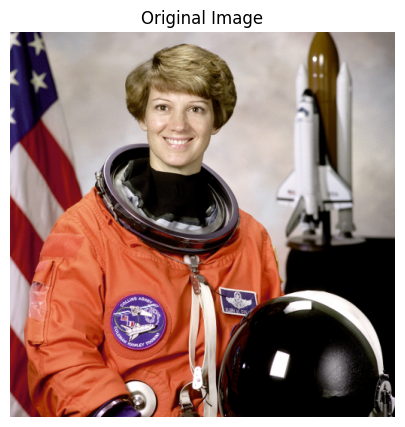

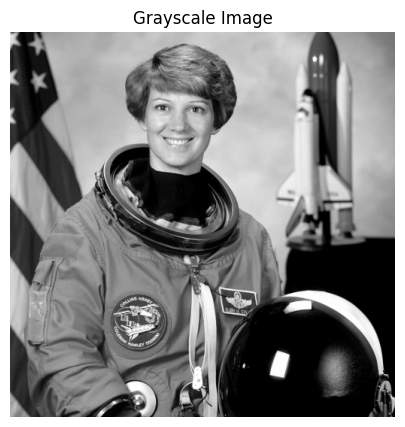

In [3]:
#2. Load a real-world sample image
image = data.astronaut()

# Convert RGB image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Display original image
plt.figure(figsize=(8, 5))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

# Display grayscale image
plt.figure(figsize=(8, 5))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

In [ ]:
Apply SIFT


In [4]:
# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and calculate descriptors
keypoints, descriptors = sift.detectAndCompute(gray, None)

print("Number of SIFT keypoints:", len(keypoints))
print("Descriptor shape:", descriptors.shape)

Number of SIFT keypoints: 1105
Descriptor shape: (1105, 128)


Display SIFT keypoints


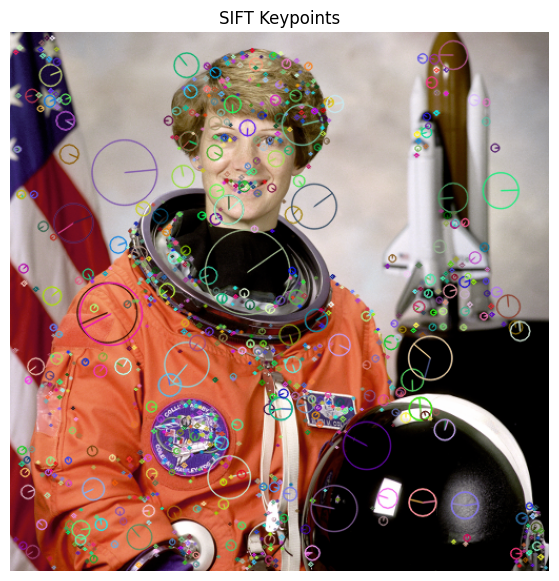

In [5]:
# Draw keypoints on the image
sift_image = cv2.drawKeypoints(
    image,
    keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(10, 7))
plt.imshow(sift_image)
plt.title("SIFT Keypoints")
plt.axis("off")
plt.show()

Apply HOG


In [6]:
# Convert image to float
gray_float = gray.astype(np.float32) / 255.0

# Extract HOG features
hog_features, hog_image = hog(
    gray_float,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True
)

print("HOG feature vector length:", len(hog_features))

HOG feature vector length: 142884


Display HOG visualization



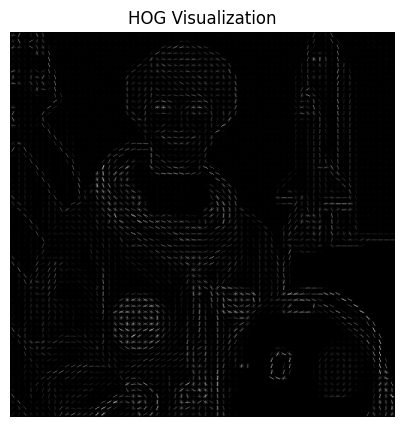

In [7]:
plt.figure(figsize=(8, 5))
plt.imshow(hog_image, cmap="gray")
plt.title("HOG Visualization")
plt.axis("off")
plt.show()

7. Compare SIFT and HOG


In [8]:
print("----- SIFT -----")
print("Number of keypoints:", len(keypoints))
print("Descriptor shape:", descriptors.shape)

print("\n----- HOG -----")
print("HOG feature vector length:", len(hog_features))

----- SIFT -----
Number of keypoints: 1105
Descriptor shape: (1105, 128)

----- HOG -----
HOG feature vector length: 142884


8. SIFT image matching


In [9]:
# Create a modified version of the image
height, width = gray.shape

M = cv2.getRotationMatrix2D(
    (width / 2, height / 2),
    12,       # rotation angle
    0.90      # scale
)

gray2 = cv2.warpAffine(gray, M, (width, height))

# Detect SIFT features in second image
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)

print("Keypoints in second image:", len(keypoints2))

Keypoints in second image: 997


9. Match SIFT descriptors


In [10]:
# Create Brute Force matcher
bf = cv2.BFMatcher()

# Find two best matches for every descriptor
matches = bf.knnMatch(descriptors, descriptors2, k=2)

# Lowe's ratio test
good_matches = []

for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

print("Total matches:", len(matches))
print("Good matches:", len(good_matches))

Total matches: 1105
Good matches: 656


10. Display matched features


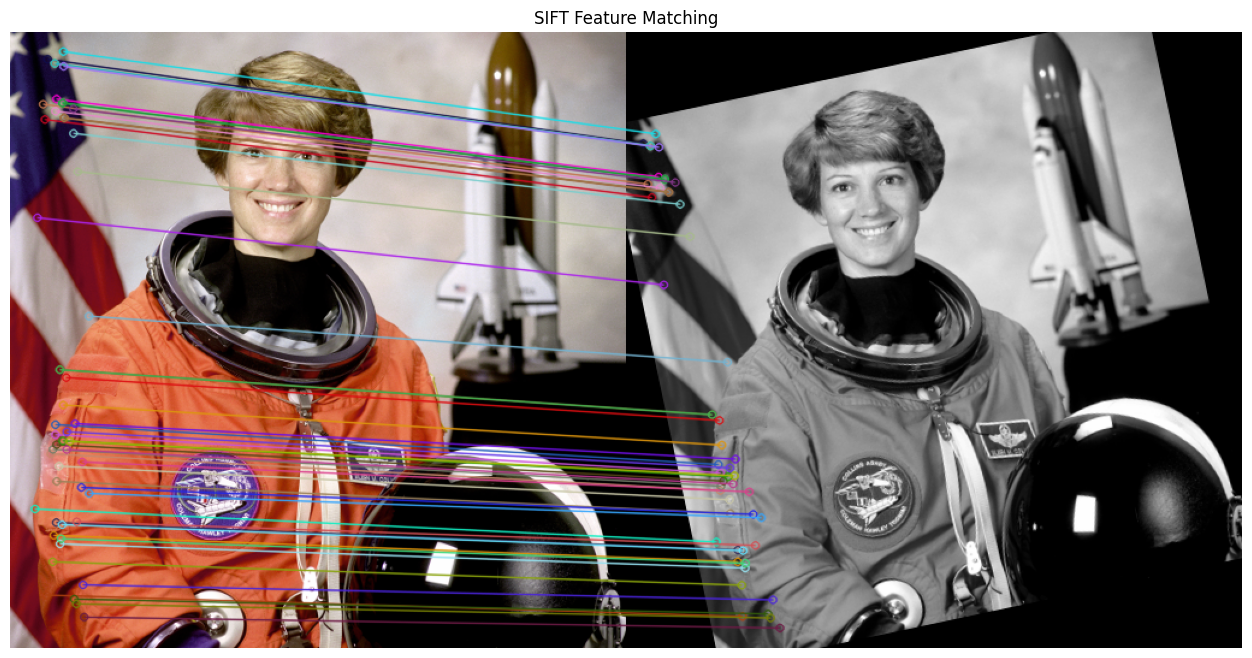

In [11]:
# Convert second grayscale image to RGB
image2_rgb = cv2.cvtColor(gray2, cv2.COLOR_GRAY2RGB)

# Draw matches
matched_image = cv2.drawMatches(
    image,
    keypoints,
    image2_rgb,
    keypoints2,
    good_matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(matched_image)
plt.title("SIFT Feature Matching")
plt.axis("off")
plt.show()

# New Section